# Quantitative phase analysis from powder diffraction

A powder pattern is a sum of phase patterns, each scaled by how much of the
phase the beam saw. Turning those scales into **weight fractions** is
quantitative phase analysis (QPA), and it is an inverse problem with several
effects acting at once — peak overlap, texture, specimen displacement, phase-
specific broadening and thermal motion, microabsorption, and material that
does not diffract at all (glass, gels, poorly ordered phases). None of them is
handled by reading peak heights.

The core relation is **Hill & Howard's** (1987): for a whole-pattern
(Rietveld-type) fit with phase scales $S_p$,

$$W_p = \frac{S_p\,(ZMV)_p}{\sum_i S_i\,(ZMV)_i},$$

with $Z M$ the cell mass and $V$ the cell volume. These are **relative**
weights of the crystalline phases — they always sum to 1, whatever fraction of
the specimen is amorphous. Every absolute statement (how much glass?) needs one
more known mass: an internal standard, a standard *addition*, or the bulk
chemistry.

| question | function |
|---|---|
| one pattern, maybe with an internal standard | `mv.exp.fit_pattern` |
| a campaign of spiked patterns; the library may miss phases (`unknown`) | `mv.exp.qpa` |
| neat and spiked specimens of the same powders, replicate preparations, bulk chemistry; the amorphous fraction is the target | `mv.exp.qpa_amorphous` |

The patterns below are synthesised with the engine's own forward model so the
answers are known; nothing in the analysis is told them.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pymatgen.core import Lattice, Structure

import matverse as mv
from matverse import _qpa as Q
from matverse import _qpa_amorphous as QA

mv.pl.set_style()

RAD = Q.parse_radiation([(1.540598, 1.0), (1.544426, 0.5)])   # Cu Ka1 / Ka2
GRID = np.arange(15.0, 90.0 + 1e-9, 0.02)

S = {
    "corundum": Structure.from_spacegroup(
        "R-3c", Lattice.hexagonal(4.759, 12.99), ["Al", "O"],
        [[0, 0, 0.352], [0.306, 0, 0.25]]),
    "stishovite": Structure.from_spacegroup(        # a dense SiO2 polymorph
        "P4_2/mnm", Lattice.tetragonal(4.18, 2.666), ["Si", "O"],
        [[0, 0, 0], [0.306, 0.306, 0]]),
    "zincite": Structure.from_spacegroup(
        "P6_3mc", Lattice.hexagonal(3.25, 5.207), ["Zn", "O"],
        [[1 / 3, 2 / 3, 0], [1 / 3, 2 / 3, 0.382]]),
    "rutile": Structure.from_spacegroup(            # a decoy: never present
        "P4_2/mnm", Lattice.tetragonal(4.594, 2.959), ["Ti", "O"],
        [[0, 0, 0], [0.305, 0.305, 0]]),
}
B_TRUE = {"corundum": 0.3, "stishovite": 0.9, "zincite": 0.6}   # Debye-Waller, A^2
NAMES = list(S)
md = mv.data.from_structures([S[n] for n in NAMES])

🔬 Starting plot initialization...
🧪 Calculators available: 12
    • emt — EMT (LGPL-2.1)
    • lj — Lennard-Jones (LGPL-2.1)
    • mace-mpa — mace-mpa (unstated)
    • mace-omat — mace-omat (unstated)
    • sevennet — sevennet (unstated)
    • chgnet — chgnet (unstated)
    • m3gnet — m3gnet (unstated)
    • m3gnet-r2scan — m3gnet-r2scan (unstated)
    • tensornet — tensornet (unstated)
    • orb — orb (unstated)
    • gpaw-pbe — gpaw-pbe (unstated)
    • gpaw-pbe-fast — gpaw-pbe-fast (unstated)
🖥️ PyTorch absent — GPU detection skipped. Machine-learned potentials need it.

                   __
   ____ ___  ____ _/ /__   _____  _____________
  / __ `__ \/ __ `/ __/ | / / _ \/ ___/ ___/ _ \
 / / / / / / /_/ / /_ | |/ /  __/ /  (__  )  __/
/_/ /_/ /_/\__,_/\__/ |___/\___/_/  /____/\___/

🔖 Version: 0.1.72   🧮 Functions: 269   📚 Tutorials: https://matverse.readthedocs.io/
✅ set_style complete.



## The forward model

`synth` mixes phases by **mass**: each phase pattern (structure factors,
Lorentz–polarisation, multiplicity, a Kα doublet, pseudo-Voigt Caglioti
profiles) is divided by its $ZMV$ and attenuated by its own Debye–Waller
factor $\exp(-2B\sin^2\theta/\lambda^2)$. Glass adds a broad hump in
proportion to its mass, there is a falling background, and counts are
Poisson. `micro_um` optionally applies **Brindley's** particle-absorption
factor $\tau_p$ (1945): grains of a phase that absorbs more than the average
($\mu_p > \bar\mu$) are seen only through their skin and are
under-represented.

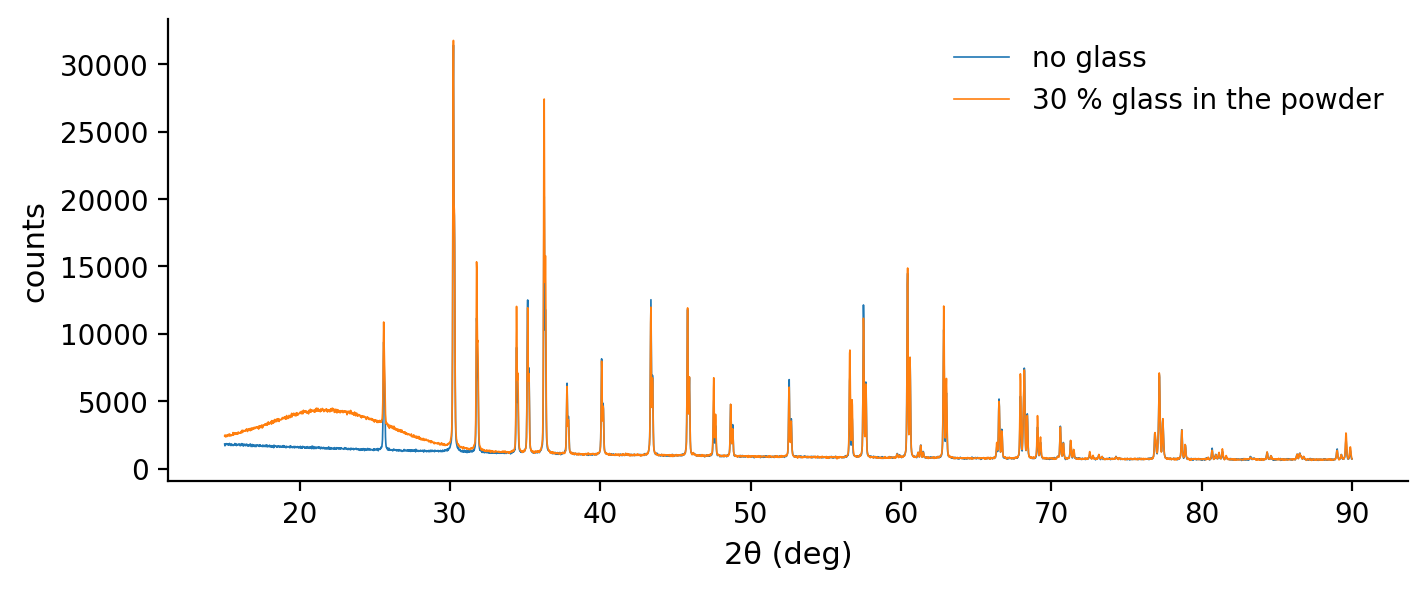

In [2]:
def synth(crystalline, glass, rng, zero=0.0, disp=0.0, micro_um=None):
    lib = Q.Library(S, RAD, (GRID[0], GRID[-1]), Q.FitOptions(), solid_solutions=False)
    tau = {n: 1.0 for n in crystalline}
    if micro_um:
        vol = {n: w / lib.rho[n] for n, w in crystalline.items()}
        mu_bar = sum(vol[n] * lib.mu[n] for n in vol) / sum(vol.values())
        tau = {n: float(Q.brindley_tau(np.array([lib.mu[n] - mu_bar]), micro_um / 2)[0])
               for n in crystalline}
    mix = np.zeros_like(GRID)
    for n, w in crystalline.items():
        st = QA.debye_waller(Q.compute_sticks(S[n], RAD.primary, (GRID[0], GRID[-1]),
                                              cutoff=0.0), B_TRUE[n], RAD.primary)
        mix += tau[n] * w / lib.zmv[n] * Q.render(st, GRID, RAD, zero, disp, 0.0,
                                                  (0.004, -0.001, 0.005), 0.45, 1.0)
    top = mix.max()
    hump = glass * 0.35 * top * np.exp(-0.5 * ((GRID - 22.0) / 4.0) ** 2)
    bg = 0.04 * top * np.exp(-(GRID - GRID[0]) / 25.0) + 0.02 * top
    return rng.poisson((mix + hump + bg) / top * 30000.0).astype(float)


rng = np.random.default_rng(0)
y_clean = synth({"corundum": 0.4, "stishovite": 0.5, "zincite": 0.1}, 0.0, rng)
y_glass = synth({"corundum": 0.3 * 0.9, "stishovite": 0.4 * 0.9, "zincite": 0.1},
                0.3 * 0.9, rng)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(GRID, y_clean, lw=0.6, label="no glass")
ax.plot(GRID, y_glass, lw=0.6, label="30 % glass in the powder")
ax.set(xlabel="2θ (deg)", ylabel="counts")
ax.legend()
plt.show()

## One pattern: `fit_pattern` and the internal standard

With a known mass fraction $w$ of a standard $k$ in the *spiked* specimen,
absolute weights follow from $W_p^{abs} = w\,m_p/m_k$, and whatever the
identified phases do not account for is the **deficit**,
$1-\sum_p W_p^{abs}/(1-w)$ of the original powder. On one pattern the deficit
cannot be split between glass and a crystalline phase missing from the
library; `fit_pattern` reports it as is.

In [3]:
for label, y in (("no glass", y_clean), ("30 % glass", y_glass)):
    t = mv.exp.fit_pattern(md, GRID, y, RAD, names=NAMES,
                           internal_standard=("zincite", 0.1),
                           solid_solutions=False)
    u = md.uns["pattern_fit"]
    print(f"{label:>10}: deficit {u['deficit']:+.3f}  Rwp {u['rwp']:.3f}  ",
          dict(zip(t.phase, t.weight_fraction.round(3))))

  no glass: deficit +0.013  Rwp 0.045   {'stishovite': 0.527, 'corundum': 0.46}


30 % glass: deficit +0.311  Rwp 0.041   {'stishovite': 0.38, 'corundum': 0.309}


The decoy (rutile) is rejected, the glass-free powder closes to ~0, and the
glassy one shows a deficit near 0.3 — the glass. Two cautions that the rest of
this page is about: the standard here absorbs like the matrix *in the
simulation* (no microabsorption); and a deficit is only "amorphous" if the
library is complete.

## A campaign: `qpa`

`mv.exp.qpa` takes every spiked pattern of a campaign at once. When a deficit
could be either glass or a phase missing from the library, it calibrates
empirical (PONKCS-style) templates of the unindexed peaks on samples where
they are the only unaccounted component and transfers them — that is why the
whole set goes in one call. Here: three samples, one without glass.

In [4]:
camp = {}
for name, glass in (("A", 0.0), ("B", 0.2), ("C", 0.35)):
    c, q = 0.45 * (1 - glass), 0.55 * (1 - glass)
    camp[name] = (GRID, synth({"corundum": c * 0.9, "stishovite": q * 0.9,
                               "zincite": 0.1}, glass * 0.9, rng))
res = mv.exp.qpa(md, camp, RAD, names=NAMES, internal_standard=("zincite", 0.1),
                 solid_solutions=False, microabsorption=False, verbose=False,
                 n_jobs=1)
res.pivot(index="sample", columns="phase", values="weight_fraction").round(3)

phase,amorphous,corundum,stishovite
sample,,,
A,NaN,0.471,0.529
B,0.207,0.372,0.421
C,0.358,0.301,0.340


`md.uns['qpa']['diagnostics']` carries, per sample, Rwp, the deficit, a
diffuse-scattering metric (is there a hump?), unindexed residual peaks, the
refined displacement, texture and Brindley τ — read them before reporting.

## Neat and spiked specimens: `qpa_amorphous`

Real laboratory practice often looks different: each powder is measured
**as prepared** ("neat") and again after a known mass of a standard was
mixed in ("spiked"); some powders are prepared several times to the same
recipe; a bulk chemical analysis (XRF) exists; and the standard is chosen
from what is at hand — sometimes a phase the powder *already contains*.
Three estimators of the amorphous fraction $G$ follow, each with its own
failure mode:

| estimator | formula | fails when |
|---|---|---|
| **standard addition** (spike $k$ already present; Copeland & Bragg 1958) | with $s=w/(1-w)$ and $R=W_k/(1-W_k)$ from each pattern: $X=s/(R_1-R_0)$, $G = 1 - X(1+R_0)$ | $R_1-R_0$ small (powder already rich in $k$, small spike): ill-conditioned. Needs the neat pattern. |
| **internal standard** (spike foreign; Bish & Howard 1988) | $G = 1 - s(1-z)/z$, $z$ the standard's relative weight | the standard absorbs much more (or less) than the matrix: microabsorption makes $z$ read low and $G$ **too low**, often negative, unless particle sizes allow a Brindley correction |
| **element balance** (bulk chemistry) | element $E$ carried by one crystalline phase $p$ only: $x_p = c_E/f_{E,p}$, $G = 1 - x_p/W_{0,p}$ | the glass also carries $E$ (then $G$ is a **lower bound**), or the analysis is biased — standardless XRF of an uncalibrated matrix easily is, by more than its quoted inter-laboratory spread |

`qpa_amorphous` (i) identifies phases on each neat pattern, (ii) refines each
sample's neat and spiked patterns **jointly** — per-phase Debye–Waller $B$,
broadening, texture and strain shared, zero/displacement/background/scales per
pattern — so that systematic profile errors largely cancel in $R_1-R_0$,
(iii) evaluates every estimator with a propagated sigma, (iv) gates the
foreign standard by its linear-absorption contrast to the matrix, keeps the
largest single-carrier element estimate per specimen, removes the spike from
the chemistry (dropped and re-closed for a foreign standard, subtracted for an
iso-phase one), (v) inflates the chemistry sigma (Birge ratio) if it disagrees
with the diffraction estimators across groups by more than its stated
accuracy, and (vi) pools by inverse variance within each **group** of
replicate preparations — once for the chemistry, whose bias is shared.

The campaign below: one recipe (30 % corundum, 45 % SiO$_2$ crystals, 25 %
silica glass), prepared three times. r1 is spiked with corundum (already in
the powder), r2 with zincite — strongly absorbing, and simulated *with*
microabsorption for 20 µm grains — r3 is neat only. The XRF reads Al$_2$O$_3$
2 wt% high, and the glass is silica, so the Si balance is not usable.

In [5]:
truth = {"corundum": 0.30, "stishovite": 0.45, "amorphous": 0.25}
c, q, g = truth["corundum"], truth["stishovite"], truth["amorphous"]


def oxides(spike=None, w=0.0, bias=2.0):
    ox = {"Al2O3": 100 * c * (1 - w) + bias, "SiO2": 100 * (q + g) * (1 - w)}
    if spike == "corundum":
        ox["Al2O3"] += 100 * w
    if spike == "zincite":
        ox["ZnO"] = 100 * w
    return ox


specimens, standards, xrf = {}, {}, {}
for name, spike, w in (("r1", "corundum", 0.2), ("r2", "zincite", 0.2), ("r3", None, 0)):
    roles = {"neat": (GRID, synth({"corundum": c, "stishovite": q}, g, rng,
                                  micro_um=20))}
    standards[name] = None
    xrf[name] = {"specimen": "neat", "oxide_wt_percent": oxides()}
    if spike:
        cr = {"corundum": c * (1 - w), "stishovite": q * (1 - w)}
        cr[spike] = cr.get(spike, 0.0) + w
        roles["spiked"] = (GRID, synth(cr, g * (1 - w), rng, disp=0.02, micro_um=20))
        standards[name] = {"phase": spike, "weight_fraction": w, "specimen": "spiked"}
        xrf[name] = {"specimen": "spiked", "oxide_wt_percent": oxides(spike, w)}
    specimens[name] = {"batch": "recipe-1", "specimens": roles}

res = mv.exp.qpa_amorphous(md, specimens, RAD, names=NAMES,
                           internal_standard=standards, bulk_chemistry=xrf,
                           chemistry_sigma=1.5, n_jobs=1)
res.pivot(index="sample", columns="phase", values="weight_fraction").round(3)

identifying phases in 3 pattern(s) (1 worker(s))


r1: identified corundum, stishovite
r2: identified corundum, stishovite
r3: identified corundum, stishovite
joint refinement of 3 sample(s)


group recipe-1: amorphous 0.2484 ± 0.0243 from 2 estimate(s)


phase,amorphous,corundum,stishovite
sample,,,
r1,0.248,0.306,0.445
r2,0.248,0.307,0.445
r3,0.248,0.305,0.446


Every estimate, used or not, is kept with its reason:

In [6]:
u = md.uns["qpa_amorphous"]
pd.set_option("display.max_colwidth", 90)
u["estimators"][["sample", "estimator", "detail", "G", "sigma", "used", "note"]].round(3)

,sample,estimator,detail,G,sigma,used,note
0,r1,iso_spike,corundum,0.266,0.030,True,
1,r1,element_balance,Al in corundum,0.203,0.046,True,spike element mass subtracted
2,r1,element_balance,Si in stishovite,-0.182,0.032,False,spike element mass subtracted; lower than another element's estimate (element likely a...
3,r2,internal_standard,zincite,0.106,0.013,False,"absorption contrast 0.95 > 0.5: microabsorption-biased without particle sizes, not used"
4,r2,element_balance,Al in corundum,0.223,0.045,True,"spike components dropped, analysis re-closed"
5,r2,element_balance,Si in stishovite,-0.153,0.031,False,"spike components dropped, analysis re-closed; lower than another element's estimate (e..."
6,r3,element_balance,Al in corundum,0.212,0.037,True,
7,r3,element_balance,Si in stishovite,-0.179,0.025,False,; lower than another element's estimate (element likely also in the amorphous fraction)


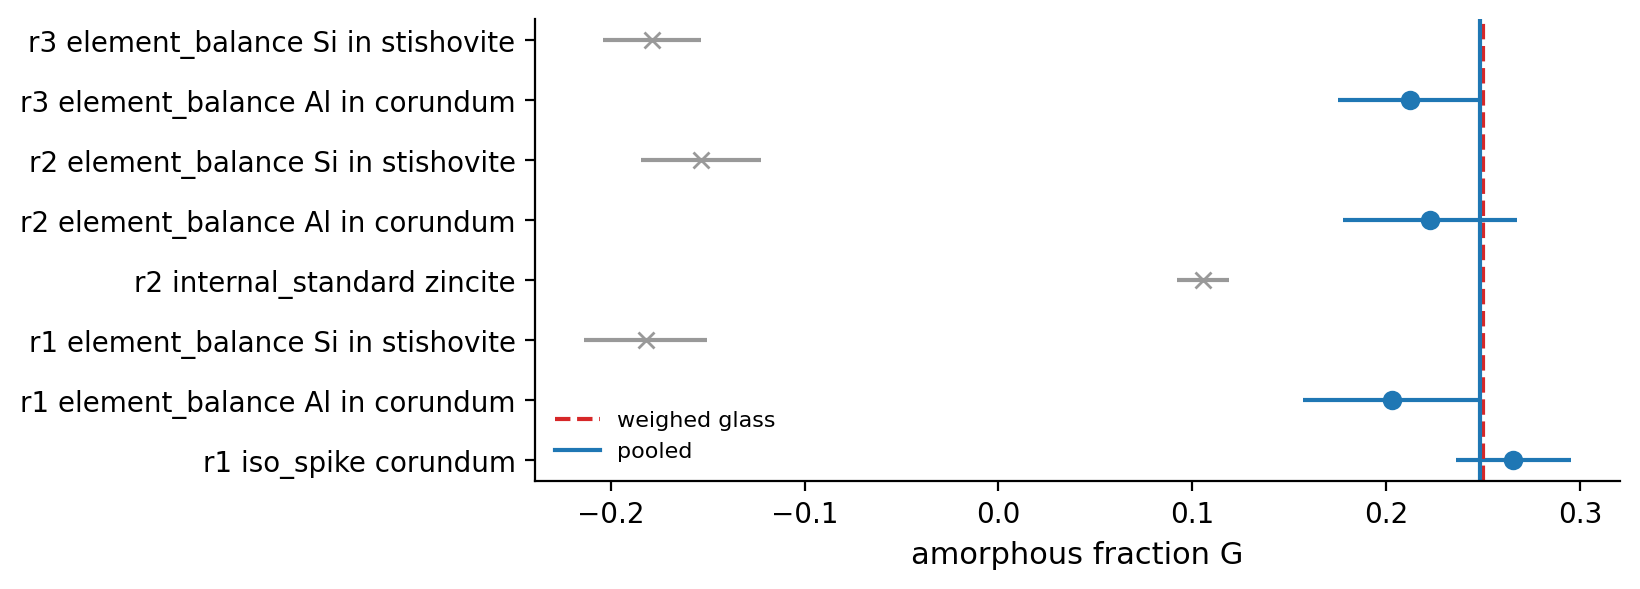

In [7]:
est = u["estimators"]
fig, ax = plt.subplots(figsize=(7, 3))
for i, r in est.reset_index(drop=True).iterrows():
    ax.errorbar(r.G, i, xerr=r.sigma, fmt="o" if r.used else "x",
                color="C0" if r.used else "0.6")
ax.axvline(truth["amorphous"], ls="--", c="C3", label="weighed glass")
ax.axvline(u["groups"].G.iloc[0], c="C0", label="pooled")
ax.set_yticks(range(len(est)), [f"{a} {b} {d}" for a, b, d in
                                zip(est["sample"], est.estimator, est.detail)])
ax.set_xlabel("amorphous fraction G")
ax.legend(fontsize=8)
plt.show()

Read it from the bottom up. The **Si balance** is strongly negative — the
glass is silica, so silicon is not confined to one crystalline phase — and is
dropped as a lower bound. The **zincite standard** reads $G$ far too low:
microabsorption, exactly the failure that makes the classical formula
dangerous with a heavy standard; with no particle sizes it is reported and not
used. The **Al balance** is biased low by the XRF error. **Standard addition**
with corundum is the cleanest estimate here; pooling all of them by their
sigmas lands on the weighed value.

Given the grain size, the foreign standard becomes usable: Brindley's τ is
applied inside Hill–Howard and the estimate is pooled.

In [8]:
res_sized = mv.exp.qpa_amorphous(md, specimens, RAD, names=NAMES,
                                 internal_standard=standards, bulk_chemistry=xrf,
                                 chemistry_sigma=1.5, particle_size_um=20.0,
                                 key_added="qpa_sized", verbose=False, n_jobs=1)
e = md.uns["qpa_sized"]["estimators"]
e[e.estimator == "internal_standard"][["sample", "G", "sigma", "used", "note"]].round(3)

,sample,G,sigma,used,note
3,r2,0.251,0.011,True,absorption contrast 0.95; Brindley-corrected


## Pitfalls

- **Relative is not absolute.** Hill–Howard weights always sum to 1 over the
  crystalline phases. Reporting them as the composition of a glassy powder
  over-states every phase by $1/(1-G)$.
- **Report the original powder.** Fractions refer to the powder before
  spiking; an iso-phase spike's mass is subtracted, not reported.
- **Microabsorption has a sign.** A standard that absorbs more than the matrix
  makes $G$ too small (even negative). Do not "fix" a negative amorphous
  fraction by clipping it and moving on; it is evidence the estimator is
  biased.
- **The quoted spread of a chemical analysis is reproducibility, not
  accuracy.** Pass `chemistry_sigma` as the absolute accuracy you believe
  (a few tenths to a couple of wt% for standardless XRF); the Birge factor
  only ever *increases* it, when the data contradict it.
- **Same recipe ≠ same pattern.** Replicates share $G$ (the glass came from
  the same lot at the same target fraction) but each keeps its own
  crystalline ratio from its own neat pattern.
- **Thermal motion is phase-specific.** Without a refined $B$ per phase the
  high-angle intensities of a soft phase are over-predicted and its scale
  under-estimated by a few percent — enough, in a difference $R_1-R_0$, to
  move $G$ by several wt%. `md.uns['qpa_amorphous']['specimens']` lists the
  refined $B$; values at the bound mean a wrong phase set.
- **Open set.** `qpa_amorphous` assumes the library covers the crystalline
  phases; unindexed residual peaks mean `mv.exp.qpa` (unknown bucket) is the
  right tool.

## References

- R. J. Hill, C. J. Howard, *J. Appl. Cryst.* **20**, 467 (1987) — ZMV weights.
- D. L. Bish, S. A. Howard, *J. Appl. Cryst.* **21**, 86 (1988) — internal standards.
- L. E. Copeland, R. H. Bragg, *Anal. Chem.* **30**, 196 (1958) — the addition method.
- L. Alexander, H. P. Klug, *Anal. Chem.* **20**, 886 (1948).
- G. W. Brindley, *Philos. Mag.* **36**, 347 (1945) — microabsorption.
- I. C. Madsen, N. V. Y. Scarlett, A. Kern, *Z. Kristallogr.* **226**, 944
  (2011) — amorphous and unknown content in QPA.
- N. V. Y. Scarlett, I. C. Madsen, *Powder Diffr.* **21**, 278 (2006) — PONKCS.
- R. T. Birge, *Phys. Rev.* **40**, 207 (1932) — consistency of estimates.